# 04. T1 × TabPFN — 작은 표 데이터용 기초 모델을 붙이면 나아지나

**근거 논문**
- Hollmann et al., *Accurate predictions on small data with a tabular foundation model*, **Nature 637 (2025)** — 표본 1만 개 이하·변수 500개 이하에서 튜닝한 부스팅보다 우수.
- Hoo et al., *The Tabular Foundation Model TabPFN Outperforms Specialized Time Series Forecasting Models Based on Simple Features* (arXiv 2501.02945, 2025) — 단순 시간 변수 + TabPFN으로 시계열 예측.

**TabPFN이 다른 점**: 우리 데이터로 가중치를 학습하지 않는다. 합성 데이터 수백만 개로 "작고 잡음 많은 표에서 예측하는 법"을 미리 배운 신경망에 **학습 구간을 예시로 보여 주고(in-context)** 바로 예측한다 → 작은 데이터에서 과적합하기 어렵다는 것이 논문의 주장. T1의 가장 큰 적이 과적합이었으므로 시험해 볼 가치가 있다.

**규정 준수**
- 입력은 **제공된 데이터(train/test CSV)로 만든 기존 피처만** 사용한다. 외부 데이터 없음, 새 피처 없음(→ 선택 편향이 늘지 않음).
- TabPFN 가중치는 실데이터가 아니라 **합성 데이터로 사전학습**된 모델 파라미터다. 라이선스 관문이 없는 공개 **v2 가중치**(Nature 논문 버전)를 쓴다.
- 매 fold에서 **그 fold의 학습 구간만** 예시로 보여 준다(검증·Test 정보 없음).

**후보 (미리 3개로 고정)**
| 후보 | 구성 | 의도 |
| --- | --- | --- |
| C1 | TabPFN 단독 — LR 쪽 핵심 9개(미국 지수·환율·유가 차이 + 검색량 심리) | 원인이 분명한 소수 신호를 TabPFN이 비선형으로 더 잘 쓰나 |
| C2 | E13의 랜덤포레스트를 TabPFN으로 교체 — TabPFN(RF 쪽 85개) 50% + LR(9개) 50% | 약한 신호 85개의 조합을 RF보다 잘 잡나 |
| C3 | E13 확률 50% + C1 확률 50% | 성격이 다른 모델의 평균으로 흔들림 감소 |

**판정 기준 (미리 정함, 하나라도 못 넘으면 E13 유지)**
1. 블록 부트스트랩 P(후보 > E13) ≥ 95%
2. CV 평균 − 표준편차 ≥ E13
3. 최근 fold 4·5 평균 ≥ E13
4. 난수 seed 10개 중 8개 이상 E13 우세 (1~3을 통과한 후보 중 OOF 1위만)

In [1]:
# train.ipynb §1~§4(데이터·피처·E13 정의)를 조용히 불러온다 (실험은 캐시로 건너뜀, experiments.csv 변경 없어야 정상)
import torch                                   # ⚠️ xgboost보다 먼저 불러온다 (macOS OpenMP 충돌로 TabPFN이 조용히 죽는 문제 방지)
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
import json, os, contextlib, io, time, warnings
import matplotlib.pyplot as plt
from IPython.display import display

_mt = os.path.getmtime('experiments.csv')
_nb = json.load(open('train.ipynb', encoding='utf-8'))
_src = [''.join(c['source']) for c in _nb['cells']]
_stop = next(i for i, (c, s) in enumerate(zip(_nb['cells'], _src)) if c['cell_type'] == 'markdown' and s.startswith('## 5. 최종'))
_show, plt.show = plt.show, (lambda *a, **k: plt.close('all'))
globals()['display'] = lambda *a, **k: None
with contextlib.redirect_stdout(io.StringIO()):
    for c, s in zip(_nb['cells'][:_stop], _src[:_stop]):
        if c['cell_type'] == 'code':
            exec(s, globals())
plt.show = _show
from IPython.display import display
plt.close('all')
assert os.path.getmtime('experiments.csv') == _mt, 'experiments.csv가 바뀜'

from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')
DEVICE = 'cpu'   # mps(Apple GPU)는 이 크기에서 멈춤 현상 → CPU (fold당 약 10~20초)
print('E13 정의 불러옴 | TabPFN v2 | device =', DEVICE)

E13 정의 불러옴 | TabPFN v2 | device = cpu


In [2]:
rng = np.random.default_rng(SEED)
y1 = Y['Target_1']; yv = y1.values; n = len(y1)
FOLDS = list(TSCV.split(np.arange(n)))                       # train.ipynb와 같은 5-fold, gap=3
VA = np.concatenate([va for _, va in FOLDS]); yva = yv[VA]
tr_ = lambda D: D[is_tr].reset_index(drop=True)

def auc(x, y):
    x, y = np.asarray(x, float), np.asarray(y); m = ~np.isnan(x)
    return roc_auc_score(y[m], x[m])

def block_idx(m, L=20):                                      # 20일 블록 부트스트랩 (자기상관 보존)
    s = rng.integers(0, m - L + 1, size=int(np.ceil(m / L)))
    return np.concatenate([np.arange(a, a + L) for a in s])[:m]

def oof(make_model, Xd):
    # make_model(): fold마다 새 모델. 학습 구간만 보고 검증 구간 예측
    p = np.full(n, np.nan)
    for tr, va in FOLDS:
        p[va] = make_model().fit(Xd.iloc[tr], y1.iloc[tr]).predict_proba(Xd.iloc[va])[:, 1]
    return p

fold_aucs = lambda p: np.array([auc(p[va], yv[va]) for _, va in FOLDS])

blocks13 = REG[('E13_t1_blend', 'Target_1')][0]
X13 = tr_(make_X(blocks13))
RF_COLS = list(make_X(FEATS['Target_1'] + ['us_last']).columns)     # E13의 RF 입력 85개
LR_COLS = list(make_X(list(LR13)).columns)                          # E13의 LR 입력 9개
pick = lambda cols: ColumnTransformer([('pick', 'passthrough', cols)])

def tabpfn(seed=0):
    return TabPFNClassifier.create_default_for_version(ModelVersion.V2, device=DEVICE, random_state=seed)

def make_e13(seed=SEED):
    return clone(REG[('E13_t1_blend', 'Target_1')][1]).set_params(rf__randomforestclassifier__random_state=seed)

def make_c1(seed=0):
    return make_pipeline(pick(LR_COLS), SimpleImputer(strategy='median'), tabpfn(seed))

def make_c2(seed=0):
    tp = make_pipeline(pick(RF_COLS), SimpleImputer(strategy='median'), tabpfn(seed))
    lr = make_pipeline(pick(LR_COLS), SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.01, max_iter=3000))
    return VotingClassifier([('tp', tp), ('lr', lr)], voting='soft')

print('E13 입력', X13.shape, '| RF 쪽', len(RF_COLS), '| LR 쪽', len(LR_COLS))

E13 입력 (924, 94) | RF 쪽 85 | LR 쪽 9


## 1. 세 후보의 검증 성능 (같은 5-fold, 같은 검증 구간)

In [3]:
t0 = time.time()
PRED = {'E13 (현재)': oof(make_e13, X13)}
assert abs(fold_aucs(PRED['E13 (현재)']).mean() - 0.6368) < 5e-4, 'E13 재현 실패'
PRED['C1 TabPFN(9개)'] = oof(make_c1, X13); print(f'C1 {time.time() - t0:.0f}초')
PRED['C2 TabPFN(85개)+LR'] = oof(make_c2, X13); print(f'C2 {time.time() - t0:.0f}초')
PRED['C3 E13+C1 평균'] = (PRED['E13 (현재)'] + PRED['C1 TabPFN(9개)']) / 2

FA = pd.DataFrame({k: fold_aucs(p) for k, p in PRED.items()}, index=[f'fold{i + 1}' for i in range(5)]).T
res = pd.DataFrame({'CV 평균': FA.mean(1), 'CV std': FA.std(1, ddof=0)})
res['평균-std'] = res['CV 평균'] - res['CV std']
res['OOF AUC'] = [auc(p[VA], yva) for p in PRED.values()]
res['fold4·5'] = FA[['fold4', 'fold5']].mean(1)
display(pd.concat([res, FA], axis=1).round(4))

C1 9초


C2 69초


,CV 평균,CV std,평균-std,OOF AUC,fold4·5,fold1,fold2,fold3,fold4,fold5
E13 (현재),0.6368,0.0329,0.6039,0.6204,0.6322,0.5991,0.6226,0.6981,0.6312,0.6332
C1 TabPFN(9개),0.6106,0.0500,0.5605,0.6062,0.6420,0.5337,0.5769,0.6581,0.6172,0.6668
C2 TabPFN(85개)+LR,0.6260,0.0670,0.5590,0.6086,0.6663,0.5598,0.5332,0.7046,0.6694,0.6632
C3 E13+C1 평균,0.6321,0.0462,0.5859,0.6201,0.6488,0.5623,0.6078,0.6927,0.6267,0.6710


## 2. 통계 검정 — 블록 부트스트랩 (E13 대비)

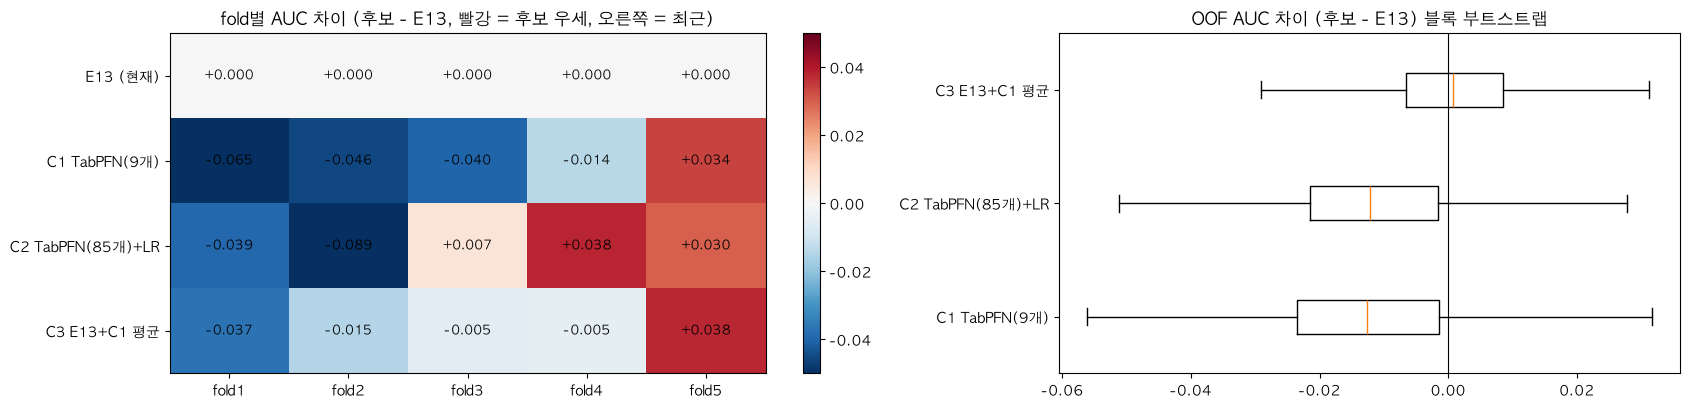

,CV 평균,CV std,평균-std,OOF AUC,fold4·5,P(> E13)
E13 (현재),0.6368,0.0329,0.6039,0.6204,0.6322,NaN
C1 TabPFN(9개),0.6106,0.0500,0.5605,0.6062,0.6420,0.2290
C2 TabPFN(85개)+LR,0.6260,0.0670,0.5590,0.6086,0.6663,0.2095
C3 E13+C1 평균,0.6321,0.0462,0.5859,0.6201,0.6488,0.5190


,1. P(>E13) ≥ 95%,2. 평균-std ≥ E13,3. fold4·5 ≥ E13,1~3 통과
C1 TabPFN(9개),❌,❌,✅,❌
C2 TabPFN(85개)+LR,❌,❌,✅,❌
C3 E13+C1 평균,❌,❌,✅,❌


In [4]:
BASE = 'E13 (현재)'
boots = {k: [] for k in PRED if k != BASE}
for _ in range(2000):
    i = block_idx(len(VA)); b = auc(PRED[BASE][VA][i], yva[i])
    for k in boots: boots[k].append(auc(PRED[k][VA][i], yva[i]) - b)
res['P(> E13)'] = [np.nan] + [np.mean(np.array(boots[k]) > 0) for k in boots]

fig, ax = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})
diff = FA.sub(FA.loc[BASE])
im = ax[0].imshow(diff, cmap='RdBu_r', vmin=-.05, vmax=.05, aspect='auto')
ax[0].set_xticks(range(5), FA.columns); ax[0].set_yticks(range(len(FA)), FA.index)
for i in range(len(FA)):
    for j in range(5): ax[0].text(j, i, f'{diff.iloc[i, j]:+.3f}', ha='center', va='center', fontsize=9)
ax[0].set_title('fold별 AUC 차이 (후보 - E13, 빨강 = 후보 우세, 오른쪽 = 최근)'); plt.colorbar(im, ax=ax[0])
ax[1].boxplot([boots[k] for k in boots], vert=False, showfliers=False); ax[1].set_yticks(range(1, len(boots) + 1), list(boots))
ax[1].axvline(0, c='k', lw=.8); ax[1].set_title('OOF AUC 차이 (후보 - E13) 블록 부트스트랩')
plt.tight_layout(); plt.show()

ok = pd.DataFrame({
    '1. P(>E13) ≥ 95%': res['P(> E13)'].drop(BASE) >= .95,
    '2. 평균-std ≥ E13': res['평균-std'].drop(BASE) >= res.loc[BASE, '평균-std'],
    '3. fold4·5 ≥ E13': res['fold4·5'].drop(BASE) >= res.loc[BASE, 'fold4·5']})
ok['1~3 통과'] = ok.all(axis=1)
display(res.round(4)); display(ok.replace({True: '✅', False: '❌'}))

## 3. seed 반복 (1~3을 통과한 후보가 있을 때만) + 판정

In [5]:
passed = list(ok.index[ok['1~3 통과']])
if not passed:
    print('→ 결론: 1~3을 통과한 후보 없음 → E13 유지 (TabPFN 미채택)')
else:
    best = res.loc[passed, 'OOF AUC'].idxmax()
    mk = {'C1 TabPFN(9개)': lambda s: oof(lambda: make_c1(s), X13),
          'C2 TabPFN(85개)+LR': lambda s: oof(lambda: make_c2(s), X13),
          'C3 E13+C1 평균': lambda s: (oof(lambda: make_e13(s), X13) + oof(lambda: make_c1(s), X13)) / 2}[best]
    wins = []
    for s in range(10):
        wins.append(fold_aucs(mk(s)).mean() > fold_aucs(oof(lambda: make_e13(s), X13)).mean())
    print(f'4. seed 반복 — {best}: {sum(wins)}/10 에서 E13 우세', '✅' if sum(wins) >= 8 else '❌')
    print('→ 결론:', f'{best} 채택 검토' if sum(wins) >= 8 else 'E13 유지 (TabPFN 미채택)')

→ 결론: 1~3을 통과한 후보 없음 → E13 유지 (TabPFN 미채택)


### 결과를 볼 때 주의
- TabPFN은 논문에서 **일반 표 데이터 수백 개** 기준으로 강했다. 주가처럼 신호가 매우 약하고(AUC 0.6대) 시기마다 바뀌는 데이터에서도 그런지는 별개의 문제이고, 이 노트북이 바로 그것을 잰다.
- 기준을 못 넘으면 "TabPFN이 나쁘다"가 아니라 **"이 데이터에서는 이미 E13이 담은 것 이상을 꺼내지 못했다"**는 뜻이다.